# 21 — Ptycho-Weak-Lensing

**Weak lensing as a spin-2 inverse problem, with a ptychographic reconstruction over overlapping pointings.** Status: `THEORETICAL:CALCULATED` — the lensing maths is ESTABLISHED (Kaiser & Squires 1993; Seitz & Schneider 2001); the pointings-as-probes ePIE reading and the intensity-only variant are THEORETICAL.

**Orientation / aperture** (observer-position): flat-sky tangent plane; the native object is a *spin-2 field* γ = γ₁ + iγ₂ (turns by 2φ under a rotation of the axes). Aperture: a 128×128 synthetic field; pointings of 48 px with step 40.

**Purpose:** a *calculated* mass map to match against published shear / dark-matter maps (the control), and a polarization vector field (Q+iU, also spin-2) as a separate image of the same experiment.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../../..'))
import numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
from ValaQuenta.modules.ptycho_weak_lensing import PtychoWeakLensingModule, maths as M
m = PtychoWeakLensingModule(); print(m.display_name, m.version, '| floor:', m.confidence_floor)

Ptycho-Weak-Lensing (shear, mass map, pointings, polarization) 0.1 | floor: THEORETICAL


## The honest checks — exact, against closed forms

In [2]:
for k, v in M.verify().items(): print(f'{k:80s} {v}')

|D| = 1 for k ≠ 0                                                                True
Gaussian halo: γ_t = κ̄(<r) − κ (max |err|)                                      0.001049924736696961
cross component γ_× ≈ 0 (rms)                                                    6.155232135211071e-06
KS round trip, κ_E error after removing the mass sheet (rms)                     0.00014936048624929028
round trip B-mode (rms)                                                          0.00010593942026027534
mass-sheet: γ blind to a constant added to κ (max |Δγ|, unpadded)                4.0611183210449854e-16
potential-born polarization is pure E (|B|/|E| rms)                              2.7897315139903313e-05
calibration: (m recovered − m injected) in sigma                                 0.9078810343881671


## Forward: a synthetic merger (two NFW halos)
κ → ψ (Poisson, FFT, zero padded) → γ = Dκ → g = γ/(1−κ). For an axisymmetric halo γ_× vanishes and γ_t = κ̄(<r) − κ.

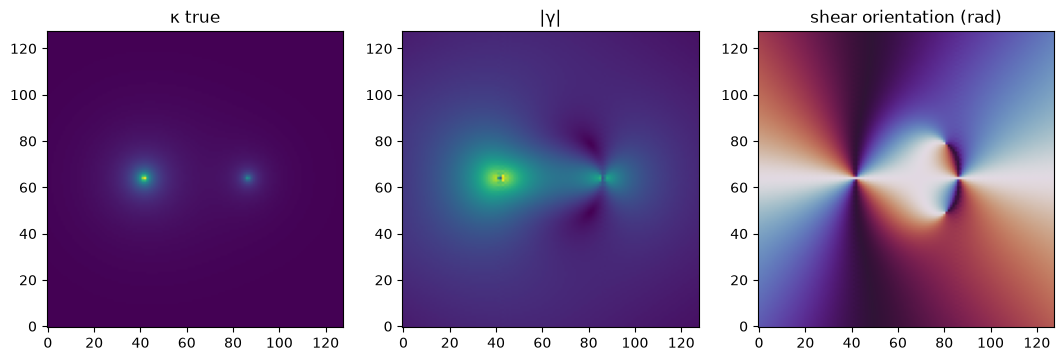

{'kappa_peak': 4.8631167858761035, 'gamma_t_profile_r=2,5,10,20,40': [0.25562, 0.14009, 0.08259, 0.04407], 'gamma_x_rms': 0.013820751920685687, 'max_magnification': 11.955325097827226}


In [3]:
n = 128; kt = M.merging_cluster(n); g = M.kappa_to_gamma(kt)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(kt, origin='lower'); ax[0].set_title('κ true'); ax[1].imshow(np.abs(g), origin='lower'); ax[1].set_title('|γ|')
ax[2].imshow(np.angle(g)/2, origin='lower', cmap='twilight'); ax[2].set_title('shear orientation (rad)'); plt.show()
print(m.run('forward', {})['result'])

## Inverse: shape-noise-limited galaxies → Kaiser–Squires
Each galaxy carries a random intrinsic ellipticity (σ_e = 0.26 per component); the shear adds exactly: ε = (ε_s + g)/(1 + g*ε_s).

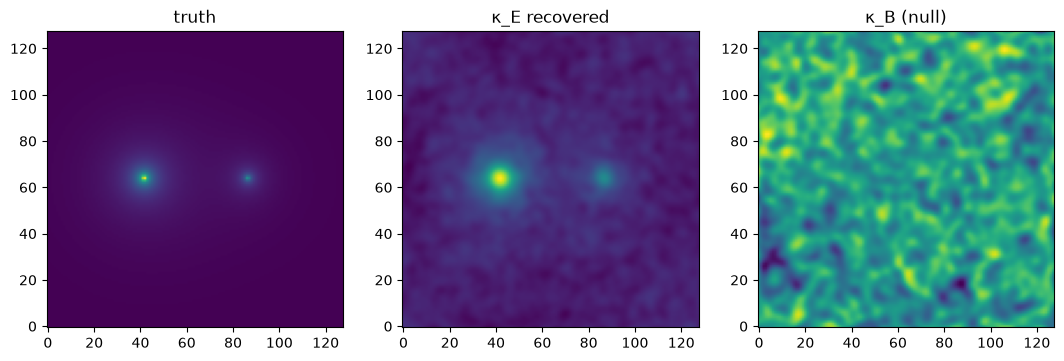

{'corr': 0.932828432648602, 'rms': 0.01475941068447717, 'peak_true': (64, 42), 'peak_rec': (64, 42), 'peak_offset_pix': 0.0} B rms 0.011379342152457474 N 196623


In [4]:
rng = np.random.default_rng(1)
cat = M.mock_catalogue(kt, 12.0, rng=rng); kE, kB = M.ks_map(cat, 2.0)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(kt, origin='lower'); ax[0].set_title('truth'); ax[1].imshow(kE, origin='lower'); ax[1].set_title('κ_E recovered'); ax[2].imshow(kB, origin='lower'); ax[2].set_title('κ_B (null)'); plt.show()
print(M.compare_maps(kt, kE), 'B rms', float(np.sqrt(np.mean(kB**2))), 'N', len(cat['e']))

## Controls: 45° rotation, shuffled orientations, calibration

In [5]:
for k, v in m.run('null_tests', {})['result'].items(): print(f'{k:50s} {v:.4f}')
print(m.run('calibrate', {})['result'])

signal corr                                        0.9328
rot45: corr of κ_E with truth                      0.0143
rot45: κ_B recovers the lens                       0.9419
shuffled orientation: corr                         0.0104
B-mode rms (should be at the noise floor)          0.0114
noise floor rms                                    0.0101
{'gamma_in': (0.03, 0.0), 'm_in': 0.05, 'c_in': 0.002, 'mean_e': (np.float64(0.03436933279865051), np.float64(4.141446792285597e-05)), 'm_recovered': np.float64(0.07897775995501699), 'stat_error_on_gamma': 0.0009575404328567832, 'N': 73728}


## Ptychography: overlapping pointings, with gaps
A pointing is a probe window `W_j`; the object is the one real field κ (B = 0); the update is ePIE/Kaczmarz over pointings. With **full coverage** the iteration and the naive stacked Kaiser–Squires reach the same fixed point (checked); with **gaps** the B = 0 constraint fills the holes and removes edge leakage.

 density  gaps  covered  corr naive  corr ptycho  rms naive  rms ptycho
     3.0     0     1.00       0.795        0.776     0.0277      0.0301
     3.0     3     0.75       0.701        0.825     0.0346      0.0301
    12.0     0     1.00       0.926        0.926     0.0155      0.0156
    12.0     3     0.75       0.864        0.923     0.0224      0.0174


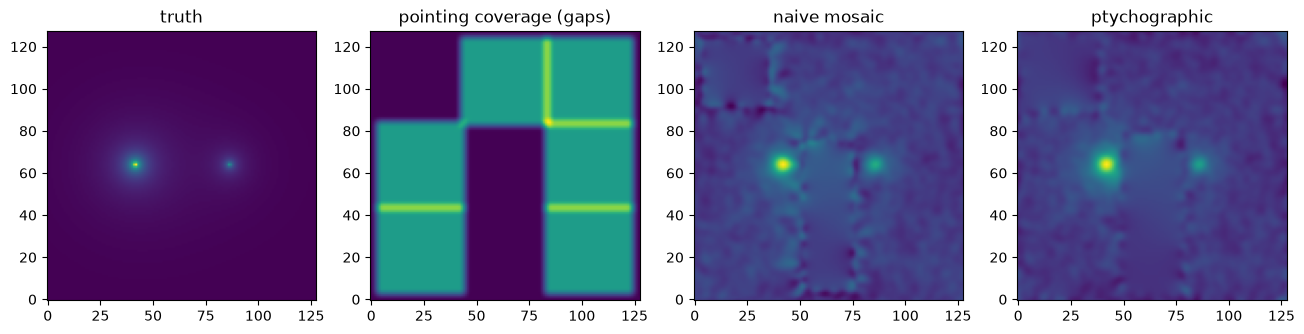

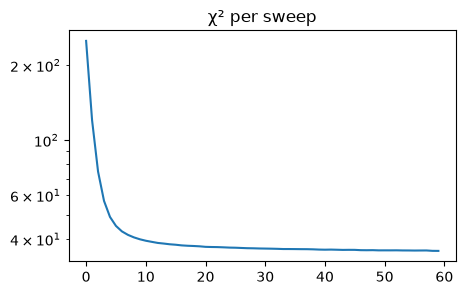

overlap error 0.05397510155496938


In [6]:
W = M.tile_windows(n, 48, 40, taper=6); rows = []
for dens in (3.0, 12.0):
    for gaps in ((), (1, 4, 6)):
        data = M.simulate_pointings(kt, W, dens, seed=2, skip=gaps); cov = sum(d['count'] for d in data) > 0.05*dens
        kn, _ = M.naive_mosaic(data); kp, h, bl = M.ptycho_reconstruct(data, n_iter=60)
        cn = M.compare_maps(kt, M.gauss_smooth(kn, 1.0), cov); cp = M.compare_maps(kt, kp, cov)
        rows.append((dens, len(gaps), cov.mean(), cn['corr'], cp['corr'], cn['rms'], cp['rms']))
print(f"{'density':>8} {'gaps':>5} {'covered':>8} {'corr naive':>11} {'corr ptycho':>12} {'rms naive':>10} {'rms ptycho':>11}")
for r in rows: print(f'{r[0]:8.1f} {r[1]:5d} {r[2]:8.2f} {r[3]:11.3f} {r[4]:12.3f} {r[5]:10.4f} {r[6]:11.4f}')
data = M.simulate_pointings(kt, W, 12.0, seed=2, skip=(1, 4, 6)); kn, _ = M.naive_mosaic(data); kp, h, bl = M.ptycho_reconstruct(data, n_iter=60)
fig, ax = plt.subplots(1, 4, figsize=(16, 4)); ax[0].imshow(kt, origin='lower'); ax[0].set_title('truth')
ax[1].imshow(sum(d['W'] for d in data), origin='lower'); ax[1].set_title('pointing coverage (gaps)'); ax[2].imshow(M.gauss_smooth(kn, 1.0), origin='lower'); ax[2].set_title('naive mosaic')
ax[3].imshow(kp, origin='lower'); ax[3].set_title('ptychographic'); plt.show()
plt.figure(figsize=(5, 3)); plt.semilogy(h); plt.title('χ² per sweep'); plt.show(); print('overlap error', M.overlap_error(data))

## Intensity-only variant (the genuine phase-retrieval case)
Keep only |γ| (orientation lost) and iterate Gerchberg–Saxton with the constraint γ = Dκ, κ real. **Finding (recorded as data):** the data residual falls to ~5e-4 from every start, but the recovered κ is right only when the start is informative (corr ≈ 0.80 from κ₀ = |γ|), the global sign of κ is undetermined (corr(κ) = −corr(−κ)), and flat or random starts stall near zero correlation. A single view is not enough — the ptychographic remedy (overlapping windows constraining each other) is OPEN here.

In [7]:
for k, v in m.run('modulus', {})['result'].items(): print(f'{k:22s}', {a: round(b, 4) if isinstance(b, float) else b for a, b in v.items()})

start = |gamma|        {'corr(kappa)': 0.8041, 'corr(-kappa)': -0.8041, 'data residual': 0.0005}
start = flat +0.05     {'corr(kappa)': -0.1289, 'corr(-kappa)': 0.1289, 'data residual': 0.0006}
start = random         {'corr(kappa)': -0.0157, 'corr(-kappa)': 0.0157, 'data residual': 0.0007}


## The second field: polarization
Q + iU is spin-2 like the shear, so the same E/B operator applies. A potential-born polarization field is pure E; the shear E-mode of the lens is an independent field — their correlation is the quantity to measure on real data (here ≈ 0 by construction).

In [8]:
for k, v in m.run('polarization', {})['result'].items(): print(f'{k:55s} {v:.4f}')

pol E/B rms (potential-born)                            0.1681
shear E/B rms (lens)                                    0.1394
corr(shear E, polarization E) independent fields        0.0474


## Source efficiency (flat ΛCDM)

In [9]:
print(m.run('efficiency', {'z_l': 0.396, 'z_s': 2.0})['result'])

{'beta': np.float64(0.7031485414999078), 'sigma_crit_Msun_per_Mpc2': np.float64(2146557864927604.0)}


## Claim ledger
| claim | status | evidence |
|---|---|---|
| γ̂ = Dκ̂, \|D\| = 1; Gaussian halo γ_t = κ̄(<r) − κ | ESTABLISHED, reproduced | `verify` |
| mass-sheet degeneracy: constant κ invisible | ESTABLISHED, reproduced | `verify` (1e-16) |
| rotation by 45° moves the lens E → B | ESTABLISHED, reproduced | `null_tests` |
| calibration (m, c) recovered within statistical error | ESTABLISHED, reproduced | `calibrate` |
| ptychographic ePIE = naive KS at full coverage; better with gaps | THEORETICAL:CALCULATED | table above (synthetic, density-dependent; at the lowest density noise dominates) |
| intensity-only (|γ|) retrieval from an uninformed start | OPEN (fails) | `modulus` |
| polarization Q+iU through the same E/B | THEORETICAL | `polarization` (synthetic) |
| no real data used yet | — | control comparison against published maps is the next step |